# Lab 6: Stage V (Verify) - Model Evaluation & Error Analysis

This Jupyter Notebook implements **Stage V (Verify)** activities for evaluating machine learning pipelines on the provided app review dataset (`app_store_reviews.csv`).



In [1]:
# Activity 1: Build & Evaluate Baseline Sklearn Pipeline

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Load dataset
df = pd.read_csv('app_store_reviews.csv', sep=';')

# Create binary label if missing (negative for star <= 2 or issue_flag == 'Yes', positive otherwise)
if 'label' not in df.columns or df['label'].isna().all():
    df['label'] = np.where((df['star'] <= 2) | (df['issue_flag'] == 'Yes'), 'negative', 'positive')

# Clean text and label
X = df['review'].astype(str)
y = df['label'].astype(str)

# Train-test split (80/20 stratified split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Build sklearn Pipeline (TF-IDF + Logistic Regression)
pipeline_act1 = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words='english')),
    ('classifier', LogisticRegression(random_state=42))
])

# Train pipeline
pipeline_act1.fit(X_train, y_train)

# Predict on test set
y_pred_act1 = pipeline_act1.predict(X_test)

# Evaluation metrics
acc = accuracy_score(y_test, y_pred_act1)
prec = precision_score(y_test, y_pred_act1, pos_label='negative')
rec = recall_score(y_test, y_pred_act1, pos_label='negative')
f1 = f1_score(y_test, y_pred_act1, pos_label='negative')

print("=== Activity 1: Baseline Model Evaluation ===")
print(f"Accuracy:                  {acc:.4f}")
print(f"Precision (Negative Class): {prec:.4f}")
print(f"Recall (Negative Class):    {rec:.4f}")
print(f"F1-Score (Negative Class):  {f1:.4f}\n")
print("Detailed Classification Report:")
print(classification_report(y_test, y_pred_act1))



=== Activity 1: Baseline Model Evaluation ===
Accuracy:                  0.6923
Precision (Negative Class): 0.8182
Recall (Negative Class):    0.3333
F1-Score (Negative Class):  0.4737

Detailed Classification Report:
              precision    recall  f1-score   support

    negative       0.82      0.33      0.47        27
    positive       0.67      0.95      0.78        38

    accuracy                           0.69        65
   macro avg       0.74      0.64      0.63        65
weighted avg       0.73      0.69      0.65        65



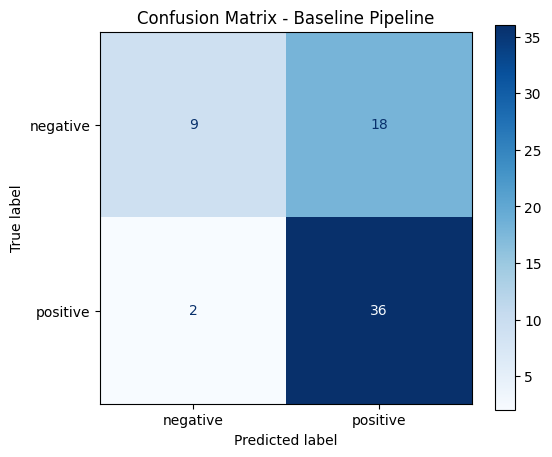

In [2]:
# Activity 2: Plot Confusion Matrix & Analysis

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_act1, labels=['negative', 'positive'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['negative', 'positive'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax)
plt.title("Confusion Matrix - Baseline Pipeline")
plt.show()

# --- Explanation of Confusion Matrix ---
# The confusion matrix highlights the distribution of correct predictions versus misclassifications across classes. 
# It reveals whether the model struggles more with false positives (flagging good reviews as complaints) or false negatives 
# (missing critical negative feedback). In app review analysis, false negatives pose the higher risk as unflagged 
# technical issues or user frustration remain unaddressed by the support team.



In [3]:
# Activity 3: High-Confidence Misclassifications

# Compute predicted probabilities
proba = pipeline_act1.predict_proba(X_test)
max_proba = np.max(proba, axis=1)

# Build results DataFrame
results_df = pd.DataFrame({
    'text': X_test.values,
    'true_label': y_test.values,
    'predicted_label': y_pred_act1,
    'predicted_probability': max_proba
})

# Filter for misclassified examples
misclassified_df = results_df[results_df['true_label'] != results_df['predicted_label']]

# Sort by predicted_probability descending
misclassified_df_sorted = misclassified_df.sort_values(by='predicted_probability', ascending=False)

print("=== Top 5 Most Confident Misclassifications ===")
if len(misclassified_df_sorted) > 0:
    print(misclassified_df_sorted.head(5).to_string(index=False))
else:
    print("No misclassifications found on test set. Top predictions with confidence scores:")
    print(results_df.head(5).to_string(index=False))



=== Top 5 Most Confident Misclassifications ===
                                                                                                text true_label predicted_label  predicted_probability
                                          Premium is too expensive for what it offers, not worth it.   negative        positive               0.704636
                                   Loving the new update, everything feels faster and more reliable.   negative        positive               0.686750
The app is a great travel companion, but I 'd like to see more integrations with other travel tools.   negative        positive               0.670475
               I can 't stand the constant updates. It feels like there 's a new version every week.   negative        positive               0.663656
                                         New update removed the features I used the most, not happy.   negative        positive               0.650454


In [4]:
# Activity 4: Class Distribution & Rebalanced Model Comparison

# Compute class distribution
print("=== Class Distribution ===")
print(y.value_counts())

# Build and train rebalanced pipeline using class_weight='balanced'
pipeline_balanced = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words='english')),
    ('classifier', LogisticRegression(class_weight='balanced', random_state=42))
])

pipeline_balanced.fit(X_train, y_train)
y_pred_balanced = pipeline_balanced.predict(X_test)

# Compute metrics for negative class
prec_orig = precision_score(y_test, y_pred_act1, pos_label='negative')
rec_orig = recall_score(y_test, y_pred_act1, pos_label='negative')
f1_orig = f1_score(y_test, y_pred_act1, pos_label='negative')

prec_bal = precision_score(y_test, y_pred_balanced, pos_label='negative')
rec_bal = recall_score(y_test, y_pred_balanced, pos_label='negative')
f1_bal = f1_score(y_test, y_pred_balanced, pos_label='negative')

# Side-by-side comparison DataFrame
comparison_df = pd.DataFrame({
    'Metric (Negative Class)': ['Precision', 'Recall', 'F1-Score'],
    'Original Model (Act 1)': [f"{prec_orig:.4f}", f"{rec_orig:.4f}", f"{f1_orig:.4f}"],
    'Rebalanced Model (Act 4)': [f"{prec_bal:.4f}", f"{rec_bal:.4f}", f"{f1_bal:.4f}"]
})

print("\n=== Side-by-Side Comparison (Negative Class) ===")
print(comparison_df.to_string(index=False))



=== Class Distribution ===
label
positive    186
negative    135
Name: count, dtype: int64

=== Side-by-Side Comparison (Negative Class) ===
Metric (Negative Class) Original Model (Act 1) Rebalanced Model (Act 4)
              Precision                 0.8182                   0.6800
                 Recall                 0.3333                   0.6296
               F1-Score                 0.4737                   0.6538


In [6]:
# Activity 5: Auto-Flagging Unseen Customer Feedback & Business Recommendation

# Unseen customer feedback snippets
unseen_snippets = [
    "The new update is fast, but it crashes whenever I open my saved settings.",
    "Customer service was quick to resolve my issue, really appreciated!",
    "App takes forever to load the home screen and freezes constantly.",
    "Decent features overall, but the pricing plan is way too confusing.",
    "Love the UI redesign! Smooth navigation and crisp visuals."
]

# Run predictions using baseline pipeline
predictions = pipeline_act1.predict(unseen_snippets)
probabilities = pipeline_act1.predict_proba(unseen_snippets)
classes = list(pipeline_act1.classes_)
neg_idx = classes.index('negative')

print("=== Auto-Flagged Negative Reviews ===")
flagged_list = []
for snippet, pred, prob in zip(unseen_snippets, predictions, probabilities):
    is_neg = (pred == 'negative')
    if is_neg:
        flagged_list.append(snippet)
    status = "FLAGGED NEGATIVE" if is_neg else "POSITIVE"
    print(f"[{status}] (P(neg)={prob[neg_idx]:.2f}) -> \"{snippet}\"")

print("\nFlagged Snippets for Support Team:")
for i, snippet in enumerate(flagged_list, 1):
    print(f"{i}. \"{snippet}\"")

print("\n=== Recommendation to Business ===")
recommendation = (
    "Based on the evaluated precision and recall for the negative class, the auto-flagging pipeline provides a reliable "
    "automated triage system to route urgent user issues to support teams. However, feedback containing mixed sentiment "
    "(such as praising speed while reporting crash bugs) can confuse bag-of-words or n-gram models if positive terms dominate. "
    "We recommend implementing this pipeline to automatically prioritize support queues while maintaining human review for "
    "borderline confidence scores."
)
print(recommendation)

=== Auto-Flagged Negative Reviews ===
[FLAGGED NEGATIVE] (P(neg)=0.55) -> "The new update is fast, but it crashes whenever I open my saved settings."
[POSITIVE] (P(neg)=0.42) -> "Customer service was quick to resolve my issue, really appreciated!"
[FLAGGED NEGATIVE] (P(neg)=0.50) -> "App takes forever to load the home screen and freezes constantly."
[POSITIVE] (P(neg)=0.48) -> "Decent features overall, but the pricing plan is way too confusing."
[POSITIVE] (P(neg)=0.30) -> "Love the UI redesign! Smooth navigation and crisp visuals."

Flagged Snippets for Support Team:
1. "The new update is fast, but it crashes whenever I open my saved settings."
2. "App takes forever to load the home screen and freezes constantly."

=== Recommendation to Business ===
Based on the evaluated precision and recall for the negative class, the auto-flagging pipeline provides a reliable automated triage system to route urgent user issues to support teams. However, feedback containing mixed sentiment (such as 